In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Download online retail dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
df = pd.read_excel(url)

# Remove missing customer IDs
df = df.dropna(subset=["CustomerID"])

# Remove cancelled invoices and invalid transactions
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate total amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print(df.head())
print("Dataset shape:", df.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalAmount  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom        15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom        22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
Dataset shape: (397884, 9)


In [2]:
# Reference date: one day after the last transaction
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

print(rfm.head())
print("Total customers:", len(rfm))

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
Total customers: 4338


In [3]:
# Reduce skewness caused by very large values
rfm_log = np.log1p(rfm)

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

print("Scaled data shape:", X.shape)

Scaled data shape: (4338, 3)


In [4]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X)

print(rfm["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64


In [5]:
dbscan = DBSCAN(eps=1.2, min_samples=8)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1       7
 0    4331
Name: count, dtype: int64


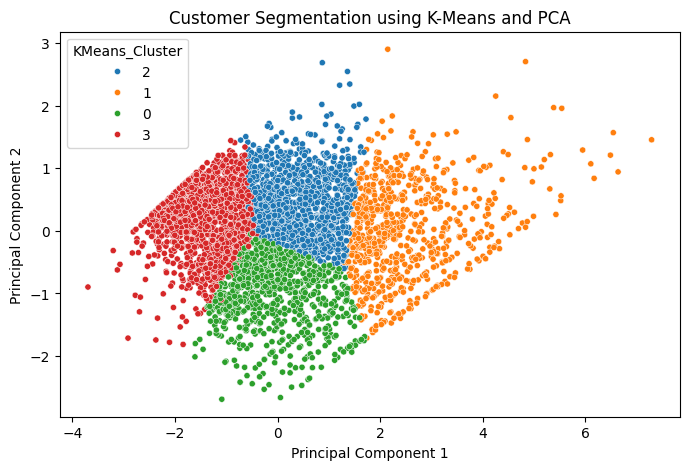

Explained variance: 0.9386124314129813


In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="tab10",
    s=20
)

plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print("Explained variance:", pca.explained_variance_ratio_.sum())

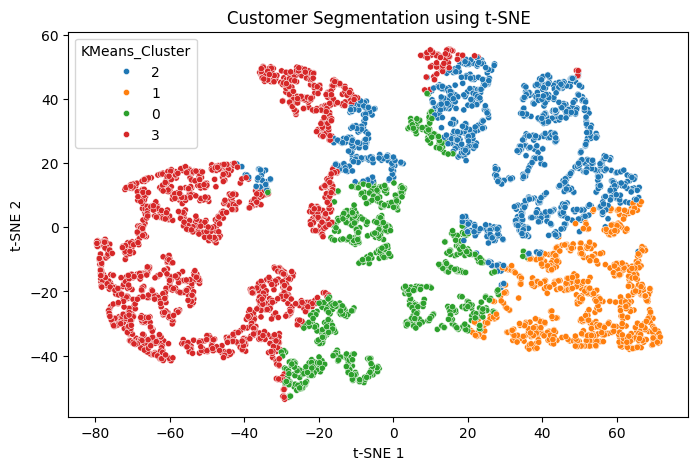

In [7]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="tab10",
    s=20
)

plt.title("Customer Segmentation using t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

In [8]:
print("K-Means cluster sizes:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

print("\nDBSCAN cluster sizes:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

# Compare average RFM values for K-Means groups
profile = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

print("\nCustomer Profiles:")
print(profile)

K-Means cluster sizes:
KMeans_Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

DBSCAN cluster sizes:
DBSCAN_Cluster
-1       7
 0    4331
Name: count, dtype: int64

Customer Profiles:
                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 18.12       2.15    551.82
1                 12.13      13.71   8074.27
2                 71.08       4.08   1802.83
3                182.50       1.32    343.45


In [9]:
# Use original RFM values for interpretation
profile = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

median_r = rfm["Recency"].median()
median_f = rfm["Frequency"].median()
median_m = rfm["Monetary"].median()

def persona(row):
    if (row["Recency"] <= median_r and
        row["Frequency"] >= median_f and
        row["Monetary"] >= median_m):
        return "Champions"
    elif row["Recency"] > median_r and row["Frequency"] < median_f:
        return "At-Risk / Inactive"
    elif row["Monetary"] >= median_m:
        return "Big Spenders"
    else:
        return "Regular Customers"

profile["Persona"] = profile.apply(persona, axis=1)

print(profile.round(2))

print("\nMarketing Strategies:")
for cluster, row in profile.iterrows():
    print(f"\nCluster {cluster}: {row['Persona']}")

    if row["Persona"] == "Champions":
        print("Offer loyalty rewards and exclusive early access.")
    elif row["Persona"] == "At-Risk / Inactive":
        print("Send re-engagement emails and personalized discounts.")
    elif row["Persona"] == "Big Spenders":
        print("Offer premium products and product recommendations.")
    else:
        print("Use product bundles and targeted promotional offers.")

                Recency  Frequency  Monetary             Persona
KMeans_Cluster                                                  
0                 18.12       2.15    551.82   Regular Customers
1                 12.13      13.71   8074.27           Champions
2                 71.08       4.08   1802.83        Big Spenders
3                182.50       1.32    343.45  At-Risk / Inactive

Marketing Strategies:

Cluster 0: Regular Customers
Use product bundles and targeted promotional offers.

Cluster 1: Champions
Offer loyalty rewards and exclusive early access.

Cluster 2: Big Spenders
Offer premium products and product recommendations.

Cluster 3: At-Risk / Inactive
Send re-engagement emails and personalized discounts.
